# Calculate $\gamma_{snow}$

This shows how $\gamma_{snow}$ is calculated from $\gamma_{temporal}$ by normalizing to a reference date pair. 

In [59]:
import numpy as np
import pandas as pd
import xarray as xr
from scipy import ndimage
import rioxarray  # noqa: F401
from rasterio.fill import fillnodata
import xrspatial as xrs
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from seaborn import set_theme
set_theme()

import sys
import os
from pathlib import Path

# import from this repo 
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


First, we setup logging to get useful information and error messages. 

In [60]:
import logging

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True 
)

Open the data cubes that were saved by the previous notebook. 

In [61]:
data_dir = "../data/"

nisar_20m = xr.open_zarr(data_dir + 'nisar/zarrs/coherence_20m.zarr')#.isel(pair=slice(1, -2))
nisar_80m = xr.open_zarr(data_dir + 'nisar/zarrs/coherence_80m.zarr')#.isel(pair=slice(1, -2))
nisar_20m = nisar_20m.rio.write_crs(nisar_20m.rio.crs, inplace=True)
nisar_80m = nisar_80m.rio.write_crs(nisar_80m.rio.crs, inplace=True)

### Cleaning 

1. Set $\gamma_{temporal}$ to nan where coherence > $\gamma_{thermal|spatial}$ 
2. Interpolate to fill in nan values, mask to watershed shape
3. Reproject nisar_20m to the 80m grid 

In [62]:
pair_vars = [var for var in nisar_20m.data_vars if 'pair' in nisar_20m[var].dims]
print(pair_vars)

nisar_20m[pair_vars] = nisar_20m[pair_vars].where(nisar_20m['coherence'] <= nisar_20m['gamma_thermal'])
nisar_80m[pair_vars] = nisar_80m[pair_vars].where(nisar_80m['coherence'] <= nisar_80m['gamma_thermal'])

nisar_20m[pair_vars] = nisar_20m[pair_vars].where(nisar_20m['coherence'] <= nisar_20m['gamma_spatial'])
nisar_80m[pair_vars] = nisar_80m[pair_vars].where(nisar_80m['coherence'] <= nisar_80m['gamma_spatial'])
nisar_80m 

['coherence', 'gamma_spatial', 'gamma_temporal', 'gamma_thermal']


<xarray.Dataset> Size: 76MB
Dimensions:         (y: 524, x: 410, pair: 14)
Coordinates:
  * y               (y) float64 4kB 4.323e+06 4.323e+06 ... 4.281e+06 4.281e+06
  * x               (x) float64 3kB 3.16e+05 3.16e+05 ... 3.486e+05 3.487e+05
  * pair            (pair) <U17 952B '20251123_20251205' ... '20260428_20260510'
    end             (pair) datetime64[ns] 112B dask.array<chunksize=(14,), meta=np.ndarray>
    start           (pair) datetime64[ns] 112B dask.array<chunksize=(14,), meta=np.ndarray>
    spatial_ref     int64 8B 0
    band            int64 8B ...
Data variables:
    canopy_2019     (y, x) float32 859kB dask.array<chunksize=(262, 205), meta=np.ndarray>
    coherence       (pair, y, x) float32 12MB dask.array<chunksize=(4, 131, 205), meta=np.ndarray>
    cover_2019      (y, x) float64 2MB dask.array<chunksize=(524, 410), meta=np.ndarray>
    elevation       (y, x) float32 859kB dask.array<chunksize=(262, 205), meta=np.ndarray>
    gamma_spatial   (pair, y, x) float64 24MB dask.array<chunksize=(4, 131, 205), meta=np.ndarray>
    gamma_temporal  (pair, y, x) float64 24MB dask.array<chunksize=(4, 131, 205), meta=np.ndarray>
    gamma_thermal   (pair, y, x) float32 12MB dask.array<chunksize=(4, 131, 205), meta=np.ndarray>

In [63]:
nisar_80m['gamma_temporal'].max().values

array(1.00346859)

In [64]:
def fill2d(arr, mask, **kwargs):
    arr = arr.copy()
    valid = ~np.isnan(arr)
    filled = fillnodata(np.where(valid, arr, 0), mask=valid.astype("uint8"), **kwargs)
    return np.where(mask, filled, np.nan)

In [65]:
valid_any = nisar_80m['coherence'].notnull().any(dim="pair")   # shape (y, x)
closed = ndimage.binary_closing(valid_any.values, structure=np.ones((3, 3)), iterations=2)
mask_80m = ndimage.binary_fill_holes(closed)
mask_80m = xr.DataArray(mask_80m, coords=valid_any.coords, dims=valid_any.dims)
# mask_80m.plot()

In [66]:
valid_any = nisar_20m['coherence'].notnull().any(dim="pair")   # shape (y, x)
closed = ndimage.binary_closing(valid_any.values, structure=np.ones((3, 3)), iterations=2)
mask_20m = ndimage.binary_fill_holes(closed)
mask_20m = xr.DataArray(mask_20m, coords=valid_any.coords, dims=valid_any.dims)
# mask_20m.plot()

In [67]:
def fill_ds(ds, mask, **kwargs):
    def fill_da(da):
        return xr.apply_ufunc(
            fill2d, da, mask,
            input_core_dims=[["y", "x"], ["y", "x"]],
            output_core_dims=[["y", "x"]],
            vectorize=True,
            kwargs=kwargs,
            output_dtypes=["float32"],
        ).transpose(*da.dims)
    return ds.map(fill_da, keep_attrs=True)

nisar_80m_filled = fill_ds(nisar_80m.load(), mask_80m, max_search_distance=20)
nisar_20m_filled = fill_ds(nisar_20m.load(), mask_20m, max_search_distance=80)
nisar_80m_filled

<xarray.Dataset> Size: 51MB
Dimensions:         (x: 410, y: 524, pair: 14)
Coordinates:
  * x               (x) float64 3kB 3.16e+05 3.16e+05 ... 3.486e+05 3.487e+05
  * y               (y) float64 4kB 4.323e+06 4.323e+06 ... 4.281e+06 4.281e+06
  * pair            (pair) <U17 952B '20251123_20251205' ... '20260428_20260510'
    end             (pair) datetime64[ns] 112B 2025-12-05T05:11:16 ... 2026-0...
    start           (pair) datetime64[ns] 112B 2025-11-23T05:11:16 ... 2026-0...
    spatial_ref     int64 8B 0
    band            int64 8B 1
Data variables:
    canopy_2019     (y, x) float32 859kB nan nan nan nan nan ... nan nan nan nan
    coherence       (pair, y, x) float32 12MB nan nan nan nan ... nan nan nan
    cover_2019      (y, x) float32 859kB nan nan nan nan nan ... nan nan nan nan
    elevation       (y, x) float32 859kB nan nan nan nan nan ... nan nan nan nan
    gamma_spatial   (pair, y, x) float32 12MB nan nan nan nan ... nan nan nan
    gamma_temporal  (pair, y, x) float32 12MB nan nan nan nan ... nan nan nan
    gamma_thermal   (pair, y, x) float32 12MB nan nan nan nan ... nan nan nan

In [68]:
nisar_20m_reprojected = nisar_20m_filled.rio.reproject_match(nisar_80m, resampling=Resampling.bilinear)
nisar_20m_reprojected

<xarray.Dataset> Size: 51MB
Dimensions:         (x: 410, y: 524, pair: 14)
Coordinates:
  * x               (x) float64 3kB 3.16e+05 3.16e+05 ... 3.486e+05 3.487e+05
  * y               (y) float64 4kB 4.323e+06 4.323e+06 ... 4.281e+06 4.281e+06
  * pair            (pair) <U17 952B '20251123_20251205' ... '20260428_20260510'
    end             (pair) datetime64[ns] 112B 2025-12-05T05:11:16 ... 2026-0...
    start           (pair) datetime64[ns] 112B 2025-11-23T05:11:16 ... 2026-0...
    band            int64 8B 1
    spatial_ref     int64 8B 0
Data variables:
    canopy_2019     (y, x) float32 859kB nan nan nan nan nan ... nan nan nan nan
    coherence       (pair, y, x) float32 12MB nan nan nan nan ... nan nan nan
    cover_2019      (y, x) float32 859kB nan nan nan nan nan ... nan nan nan nan
    elevation       (y, x) float32 859kB nan nan nan nan nan ... nan nan nan nan
    gamma_spatial   (pair, y, x) float32 12MB nan nan nan nan ... nan nan nan
    gamma_temporal  (pair, y, x) float32 12MB nan nan nan nan ... nan nan nan
    gamma_thermal   (pair, y, x) float32 12MB nan nan nan nan ... nan nan nan

In [69]:
# for var in nisar_20m.data_vars:
#     nisar_20m[var].rio.write_nodata(np.nan, inplace=True)
# nisar_20m_filled = nisar_20m.rio.interpolate_na(method="nearest")

In [70]:
nisar_80m = nisar_80m_filled 
nisar_20m = nisar_20m_filled

### Coherence patterns in the reference pair

Investigate how raw coherence in the reference pair varies with elevation, vegetation (canopy height), and aspect. We use the 80 m grid, and derive aspect from the DEM.

In [71]:
ref_pair = '20260110_20260122'

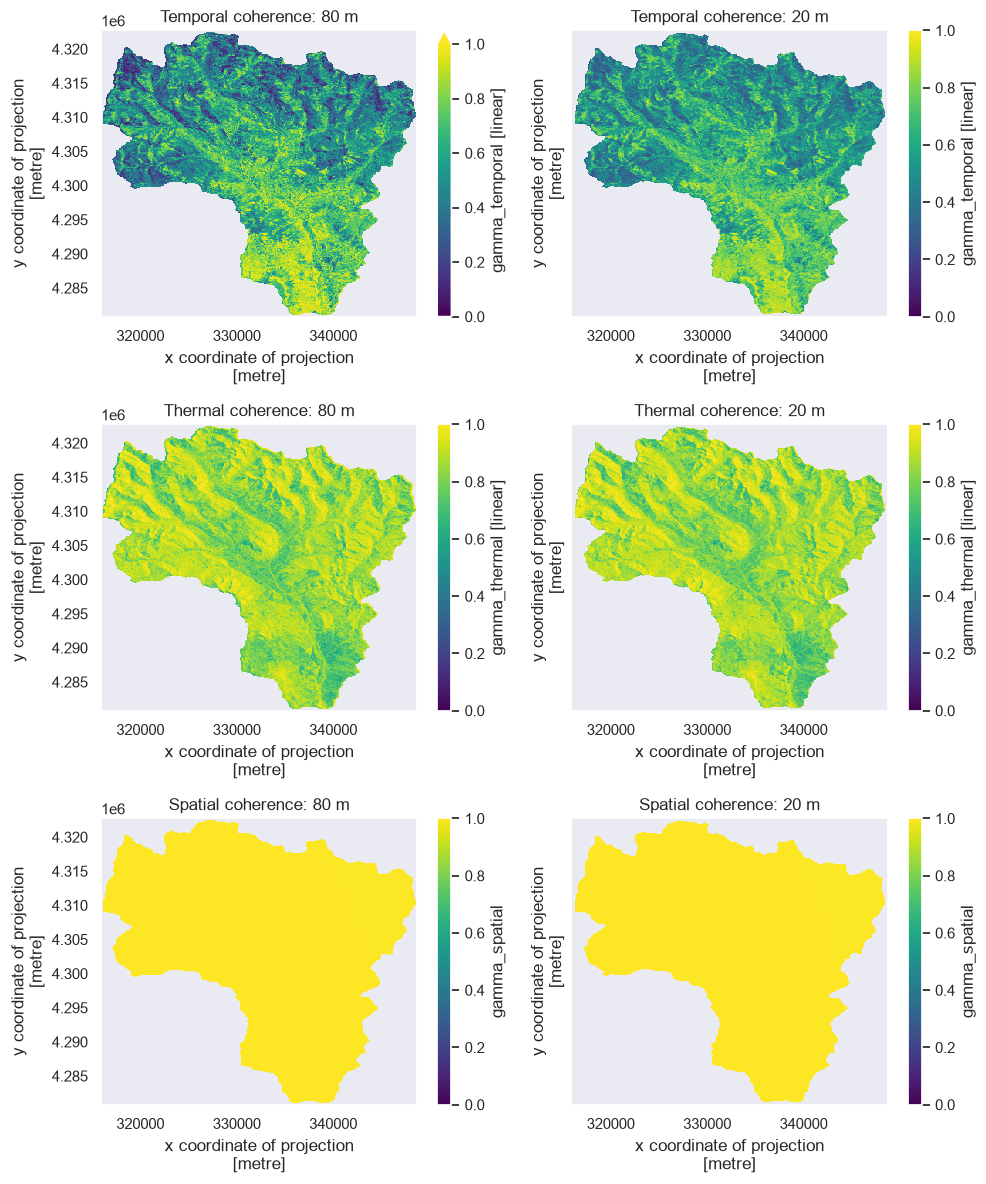

In [72]:

fig, axes = plt.subplots(3, 2, figsize=(10, 4*3), sharey=True)

nisar_80m_filled.sel(pair=ref_pair)['gamma_temporal'].plot(ax=axes[0, 0], vmin=0, vmax=1, robust=True)
nisar_80m_filled.sel(pair=ref_pair)['gamma_thermal'].plot(ax=axes[1, 0], vmin=0, vmax=1, robust=True)
nisar_80m_filled.sel(pair=ref_pair)['gamma_spatial'].plot(ax=axes[2, 0], vmin=0, vmax=1, robust=True)
axes[0, 0].set_title('Temporal coherence: 80 m')
axes[1, 0].set_title('Thermal coherence: 80 m')
axes[2, 0].set_title('Spatial coherence: 80 m')

nisar_20m_reprojected.sel(pair=ref_pair)['gamma_temporal'].plot(ax=axes[0, 1], vmin=0, vmax=1, robust=True)
nisar_20m_reprojected.sel(pair=ref_pair)['gamma_thermal'].plot(ax=axes[1, 1], vmin=0, vmax=1, robust=True)
nisar_20m_reprojected.sel(pair=ref_pair)['gamma_spatial'].plot(ax=axes[2, 1], vmin=0, vmax=1, robust=True)
axes[0, 1].set_title('Temporal coherence: 20 m')
axes[1, 1].set_title('Thermal coherence: 20 m')
axes[2, 1].set_title('Spatial coherence: 20 m')

plt.tight_layout()
plt.show()

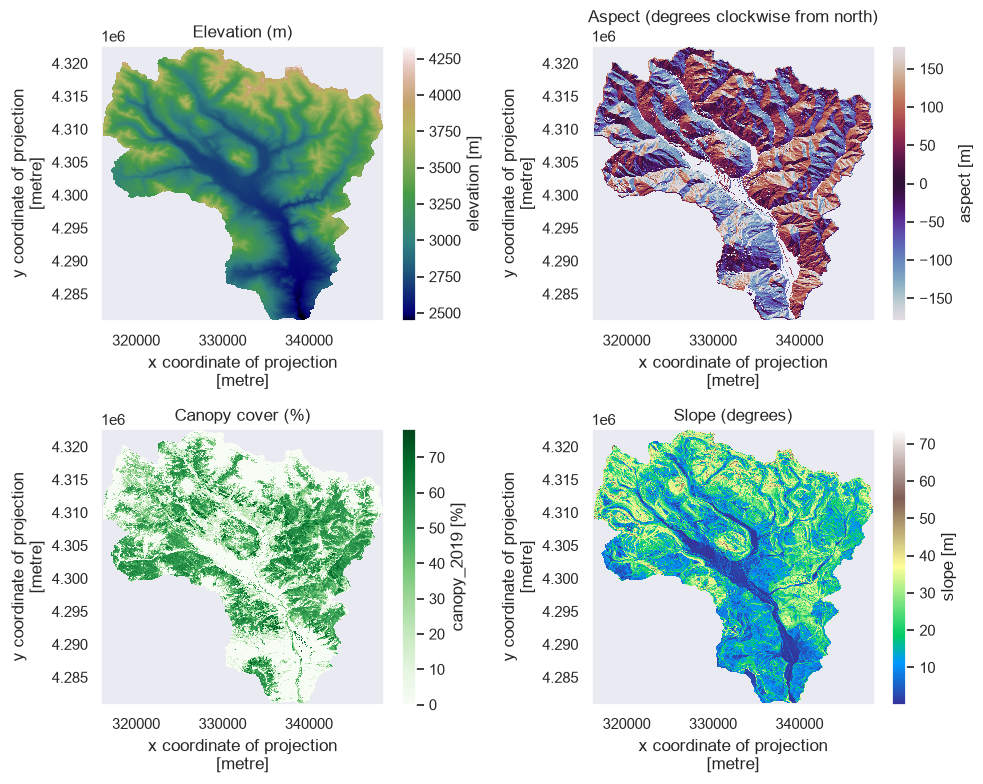

In [73]:
aspect = xrs.aspect(nisar_20m_filled['elevation']) - 180
slope = xrs.slope(nisar_20m_filled['elevation'])

fig, ax = plt.subplots(2, 2, figsize=(10, 8)) 

nisar_20m_filled['elevation'].plot(ax=ax[0, 0], cmap='gist_earth')
nisar_20m_filled['canopy_2019'].plot(ax=ax[1, 0], cmap='Greens')
aspect.where(slope > 3).plot(ax=ax[0, 1], cmap='twilight', vmin=-180, vmax=180)
slope.plot(ax=ax[1, 1], cmap='terrain')
ax[0, 0].set_title('Elevation (m)')
ax[1, 0].set_title('Canopy cover (%)')
ax[0, 1].set_title('Aspect (degrees clockwise from north)')
ax[1, 1].set_title('Slope (degrees)')

plt.tight_layout()
plt.show()

In [74]:
# Aspect (degrees clockwise from north) from the DEM; the grid is projected (metres) so this is valid directly
ds_ref = nisar_80m.sel(pair=ref_pair)
slope = xrs.slope(ds_ref['elevation'])
aspect = xrs.aspect(ds_ref['elevation']).where(slope > 5)  

# Flatten to a table of valid pixels (aspect is -1 for flat cells, so drop those)
df = pd.DataFrame({
    'coherence': ds_ref['gamma_temporal'].values.ravel(),
    'elevation': ds_ref['elevation'].values.ravel(),
    'canopy': ds_ref['canopy_2019'].values.ravel(),
    'aspect': aspect.values.ravel(),
}).dropna()
df = df[df['aspect'] >= 0]
print(f"{len(df):,} valid pixels")
df.describe()

106,394 valid pixels


,coherence,elevation,canopy,aspect
count,106394.000000,106394.000000,106394.000000,106394.000000
mean,0.567969,3178.266357,26.995554,176.452744
std,0.209424,321.289490,23.242144,96.859962
min,0.012745,2444.310791,0.000000,0.000671
25%,0.415081,2932.135498,0.000000,87.847607
50%,0.570132,3163.529785,26.000000,184.227226
75%,0.731333,3409.561157,50.000000,254.219826
max,1.003469,4318.436523,77.000000,359.999237


/var/folders/56/xwx32vfs5n52kr88xj4db_br0000gp/T/ipykernel_4123/281814026.py:15: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  sc = ax3.scatter(np.deg2rad(sample['aspect']), sample['coherence'],


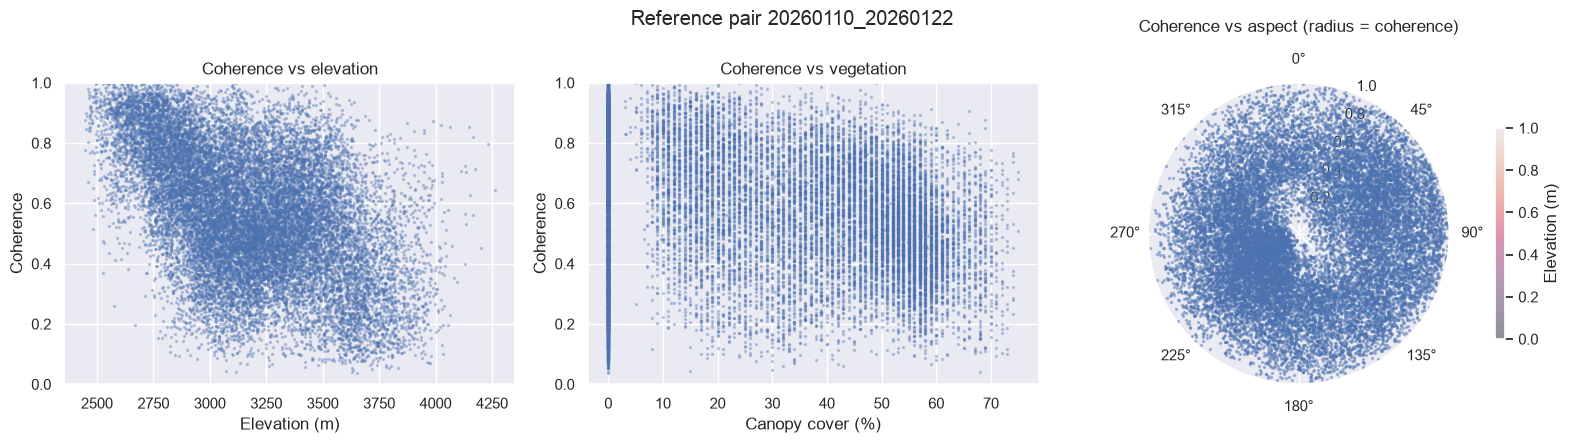

In [75]:
sample = df.sample(n=min(20000, len(df)), random_state=0)

fig = plt.figure(figsize=(16, 4.5))
ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2)
ax3 = fig.add_subplot(1, 3, 3, projection='polar')

ax1.scatter(sample['elevation'], sample['coherence'], s=2, alpha=0.3)
ax1.set(xlabel='Elevation (m)', ylabel='Coherence', title='Coherence vs elevation', ylim=(0, 1))

ax2.scatter(sample['canopy'], sample['coherence'], s=2, alpha=0.3)
ax2.set(xlabel='Canopy cover (%)', ylabel='Coherence', title='Coherence vs vegetation', ylim=(0, 1))

# Compass rose: angle = aspect (north up, clockwise), radius = coherence
sc = ax3.scatter(np.deg2rad(sample['aspect']), sample['coherence'],
                 s=2, alpha=0.4, cmap='viridis')
ax3.set_theta_zero_location('N')
ax3.set_theta_direction(-1)
ax3.set_rlim(0, 1)
ax3.set_title('Coherence vs aspect (radius = coherence)', pad=15)
fig.colorbar(sc, ax=ax3, label='Elevation (m)', shrink=0.7, pad=0.1)

fig.suptitle(f'Reference pair {ref_pair}')
plt.tight_layout()

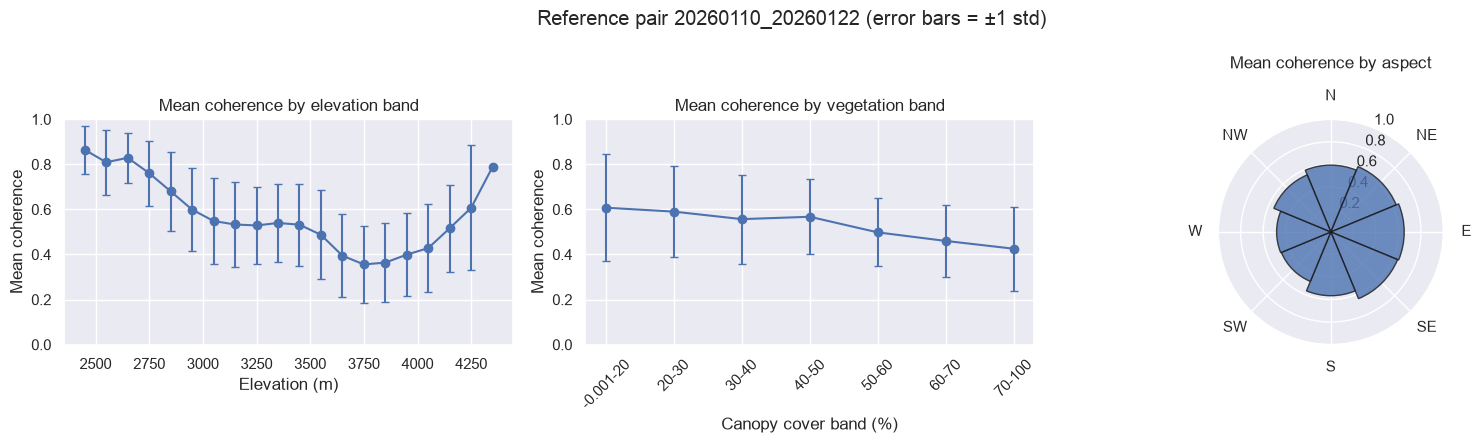

In [76]:
def band_stats(values, coherence, bins):
    """Mean/std of coherence and pixel count within bins of `values`."""
    cut = pd.cut(values, bins=bins, include_lowest=True)
    g = coherence.groupby(cut, observed=True).agg(['mean', 'std', 'count'])
    g['mid'] = [iv.mid for iv in g.index]
    return g

elev_bins = np.arange(np.floor(df['elevation'].min() / 100) * 100, df['elevation'].max() + 100, 100)  # 100 m bands
canopy_bins = [0, 20, 30, 40, 50, 60, 70, 100]                                           # canopy cover (%)
aspect_bins = np.arange(-22.5, 360, 45)                                                                # 8 compass sectors centred on N, NE, ...

# shift aspect so north (337.5-360 and 0-22.5) falls in a single bin
aspect_shifted = (df['aspect'] + 22.5) % 360 - 22.5

elev_stats = band_stats(df['elevation'], df['coherence'], elev_bins)
canopy_stats = band_stats(df['canopy'], df['coherence'], canopy_bins)
aspect_stats = band_stats(aspect_shifted, df['coherence'], aspect_bins)

fig = plt.figure(figsize=(16, 4.5))
ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2)
ax3 = fig.add_subplot(1, 3, 3, projection='polar')

ax1.errorbar(elev_stats['mid'], elev_stats['mean'], yerr=elev_stats['std'], fmt='o-', capsize=3)
ax1.set(xlabel='Elevation (m)', ylabel='Mean coherence', title='Mean coherence by elevation band', ylim=(0, 1))

ax2.errorbar(np.arange(len(canopy_stats)), canopy_stats['mean'], yerr=canopy_stats['std'], fmt='o-', capsize=3)
ax2.set_xticks(np.arange(len(canopy_stats)))
ax2.set_xticklabels([f"{iv.left:g}-{iv.right:g}" for iv in canopy_stats.index], rotation=45)
ax2.set(xlabel='Canopy cover band (%)', ylabel='Mean coherence', title='Mean coherence by vegetation band', ylim=(0, 1))

# Compass rose of mean coherence per aspect sector
theta = np.deg2rad(aspect_stats['mid'] % 360)
ax3.bar(theta, aspect_stats['mean'], width=np.deg2rad(45), alpha=0.8, edgecolor='k')
ax3.set_theta_zero_location('N')
ax3.set_theta_direction(-1)
ax3.set_xticks(np.deg2rad(np.arange(0, 360, 45)))
ax3.set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax3.set_rlim(0, 1)
ax3.set_title('Mean coherence by aspect', pad=15)

fig.suptitle(f'Reference pair {ref_pair} (error bars = ±1 std)')
plt.tight_layout()

# pd.concat({'elevation': elev_stats, 'canopy': canopy_stats, 'aspect': aspect_stats})[['mean', 'std', 'count']]

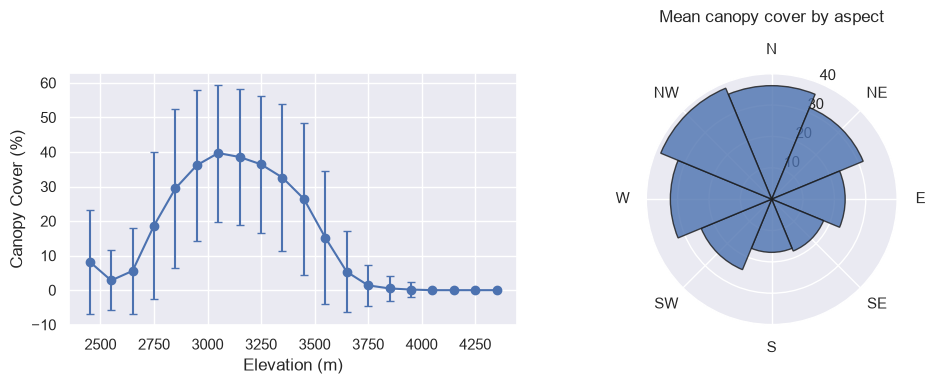

In [77]:
# plot vegetation by elevation band 
veg_elev = band_stats(df['elevation'], df['canopy'], elev_bins)
veg_aspect = band_stats(aspect_shifted, df['canopy'], aspect_bins)

fig= plt.figure(figsize=(15, 4))
ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2, projection='polar')

ax1.errorbar(veg_elev['mid'], veg_elev['mean'], yerr=veg_elev['std'], fmt='o-', capsize=3)
ax1.set_xlabel('Elevation (m)')
ax1.set_ylabel('Canopy Cover (%)')

ax2.bar(np.deg2rad(veg_aspect['mid'] % 360), veg_aspect['mean'], width=np.deg2rad(45), alpha=0.8, edgecolor='k')
ax2.set_theta_zero_location('N')
ax2.set_theta_direction(-1)
ax2.set_xticks(np.deg2rad(np.arange(0, 360, 45)))
ax2.set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax2.set_title('Mean canopy cover by aspect', pad=15)

plt.tight_layout()
plt.show()

In [78]:
# plot where snow for ref_pair is less than other pairs 
greater = nisar_80m['gamma_temporal'].where(nisar_80m['gamma_temporal'].sel(pair=ref_pair) < nisar_80m['gamma_temporal'])
# greater

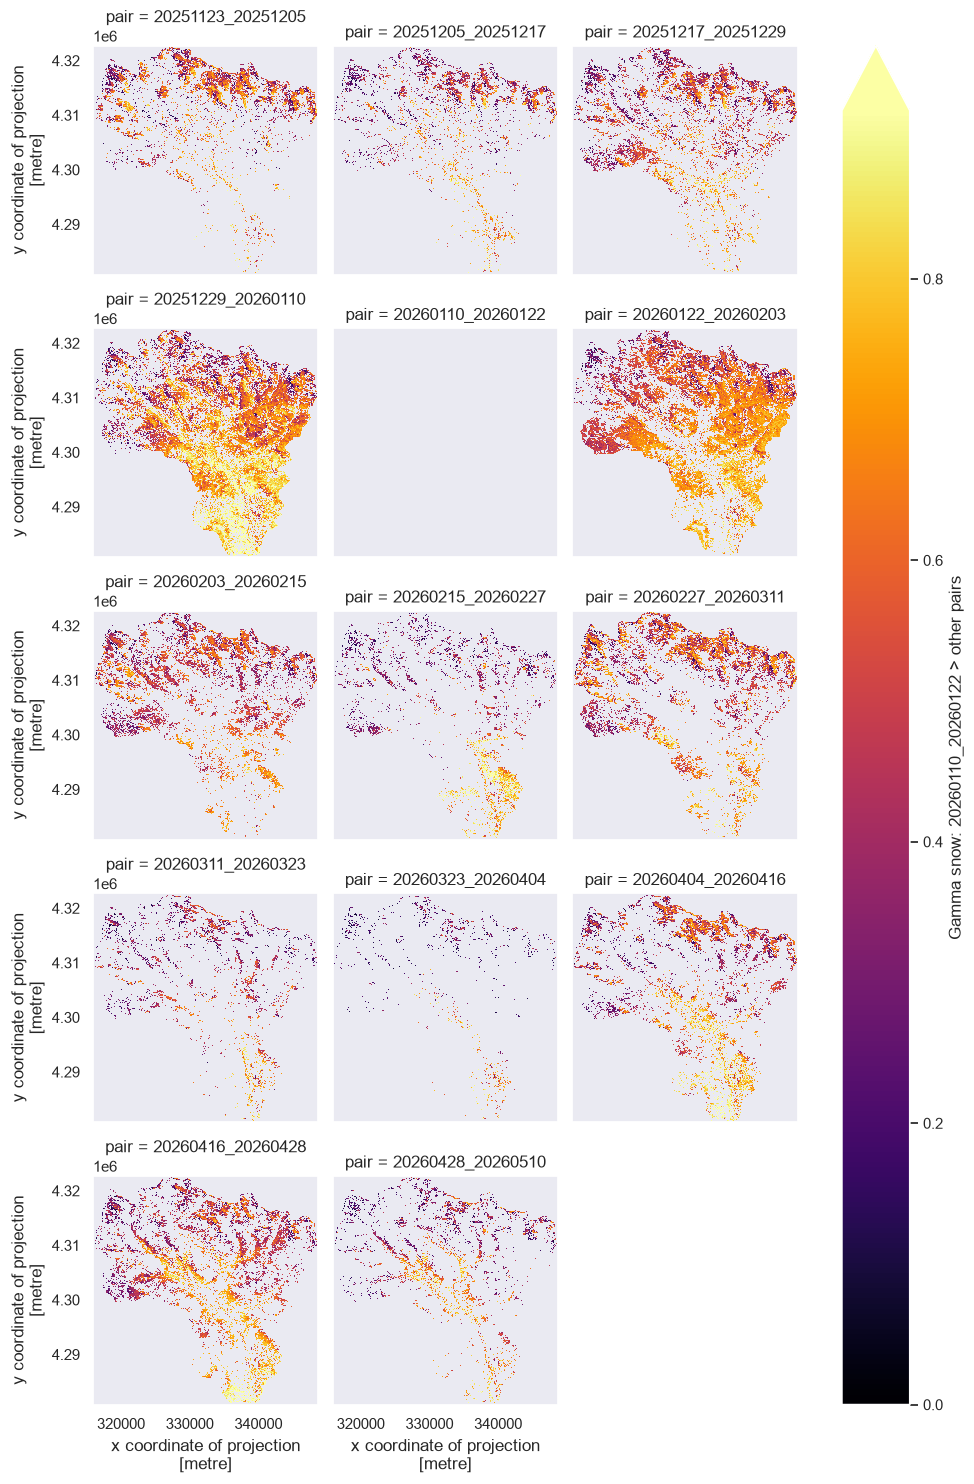

In [79]:
greater.plot(col='pair', col_wrap=3, robust=True, cmap='inferno', cbar_kwargs={'label': f'Gamma snow: {ref_pair} > other pairs'}, vmin=0)

Divide $\gamma_{temporal}$ by its value for the reference pair to get $\gamma_{snow}$. 

In [86]:
ref_pair = '20260110_20260122'

nisar_80m['gamma_snow'] = nisar_80m['gamma_temporal'] / nisar_80m.sel(pair=ref_pair)['gamma_temporal']
nisar_20m['gamma_snow'] = nisar_20m['gamma_temporal'] / nisar_20m.sel(pair=ref_pair)['gamma_temporal']
nisar_20m_reprojected = nisar_20m_filled.rio.reproject_match(nisar_80m, resampling=Resampling.bilinear)
nisar_20m_reprojected['gamma_snow'] = nisar_20m_reprojected['gamma_temporal'] / nisar_20m_reprojected.sel(pair=ref_pair)['gamma_temporal']

In [81]:
nisar_80m['gamma_snow_80div20'] = nisar_80m['gamma_temporal'] / nisar_20m_reprojected['gamma_temporal']
# nisar_20m['gamma_snow'] = nisar_20m['gamma_temporal'] / nisar_20m_reprojected['gamma_temporal']

Plot $\gamma_{snow}$ for both grids. 

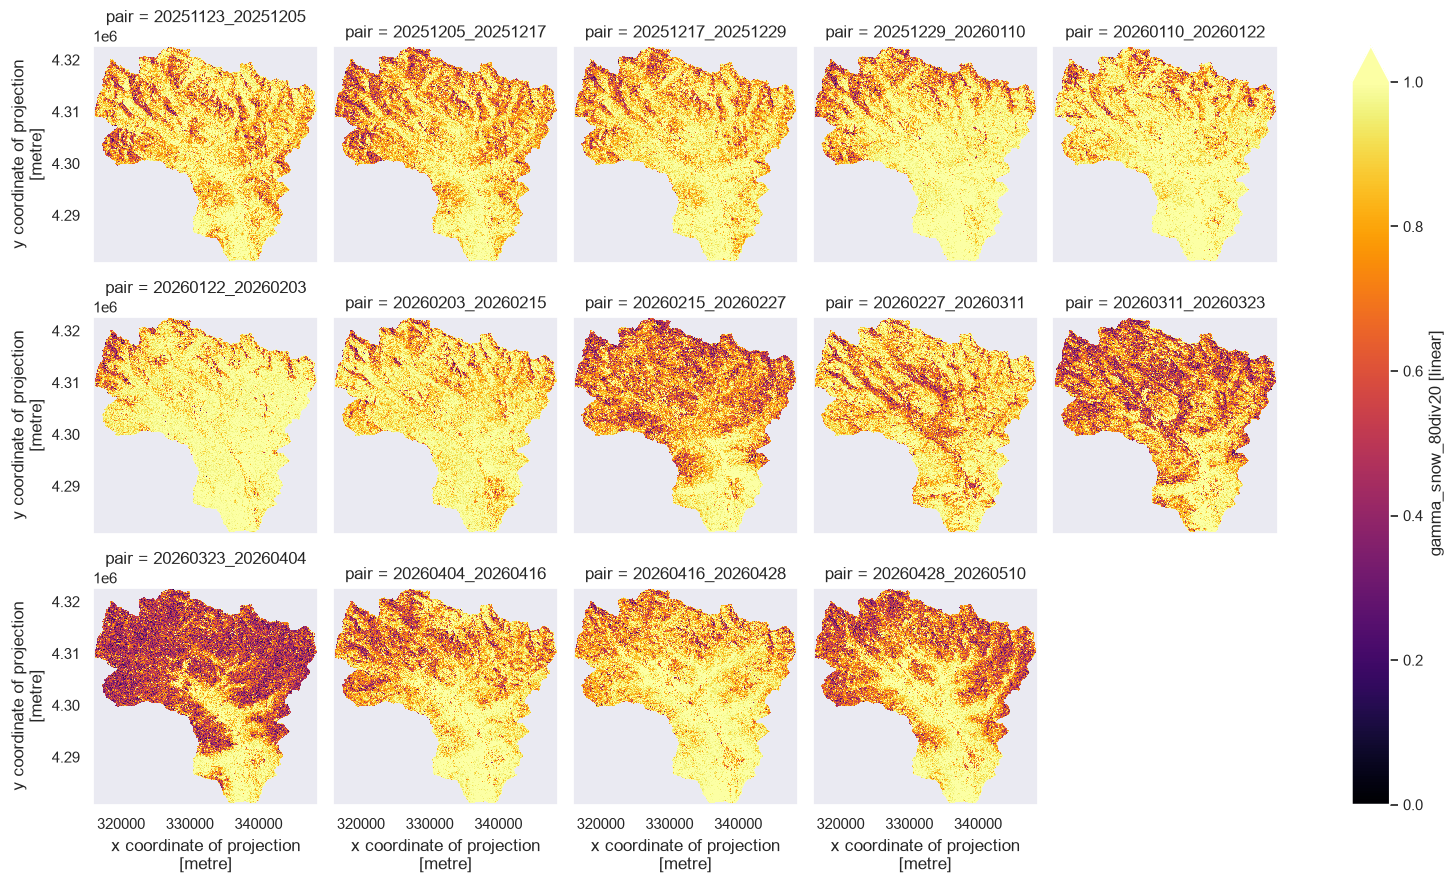

In [92]:
nisar_80m['gamma_snow_80div20'].plot(col='pair', col_wrap=5, cmap='inferno', vmin=0, vmax=1)
# nisar_20m['gamma_snow'].plot(col='pair', col_wrap=4, cmap='inferno', vmin=0, vmax=1)

In [ ]:
nisar_80m['gamma_snow'].plot(col='pair', col_wrap=4, cmap='inferno', vmin=0, vmax=1)

SyntaxError: invalid syntax (351324931.py, line 1)

In [26]:
# import mpmath as mp

# mp.mp.dps = 30
# L20, L80 = 23, 162  # effective looks from the paper (Sec. 3.6)

# def expected_sample_coh(gamma, L):
#     """Eq. 8: E{gamma_hat | gamma, L} (Bamler & Hartl 1998, Eq. 62)."""
#     g2 = mp.mpf(gamma) ** 2
#     pref = mp.gamma(L) * mp.gamma(mp.mpf(3) / 2) / mp.gamma(L + mp.mpf(1) / 2)
#     return float(pref * mp.hyp3f2(1.5, L, L, L + 0.5, 1, g2) * (1 - g2) ** L)

# def make_inverse(L, n=400):
#     """Build the forward lookup table once, return a function that inverts it (Eq. 9)."""
#     g_true = np.linspace(0, 0.9999, n)
#     e_obs = np.array([expected_sample_coh(g, L) for g in g_true])  # monotonic increasing
#     def inverse(gamma_hat):
#         # values below E{gamma_hat | gamma=0} -> 0 (pure noise); above table max -> ~1
#         return np.interp(gamma_hat, e_obs, g_true, left=0.0, right=1.0)
#     return inverse

# inv20 = make_inverse(L20)
# inv80 = make_inverse(L80)

# def debias(da, inverse):
#     return xr.apply_ufunc(
#         inverse, da,
#         dask="parallelized", output_dtypes=[float], keep_attrs=True,
#     )

# # --- inputs: coh20 (20 m grid), coh80 (80 m grid), both DataArrays with x/y dims ---

# # If the coarsened grid isn't pixel-aligned with the GUNW 80 m grid, snap it:
# # coh20_80 = coh20_80.interp(x=coh80.x, y=coh80.y, method="nearest")

# # 2) De-bias each resolution (Eq. 9)
# g20_tilde = debias(nisar_20m_reprojected["coherence"], inv20)
# g80_tilde = debias(nisar_80m["coherence"], inv80)

# # 3) Corrected difference (Eq. 10): estimate of sub-window variability coherence loss
# dgamma = g20_tilde - g80_tilde
# dgamma.name = "corrected_gamma20_minus_gamma80"

In [27]:
# dgamma

Compare the two grids by differencing them. 

In [85]:
nisar_20m_reprojected

<xarray.Dataset> Size: 51MB
Dimensions:         (x: 410, y: 524, pair: 14)
Coordinates:
  * x               (x) float64 3kB 3.16e+05 3.16e+05 ... 3.486e+05 3.487e+05
  * y               (y) float64 4kB 4.323e+06 4.323e+06 ... 4.281e+06 4.281e+06
  * pair            (pair) <U17 952B '20251123_20251205' ... '20260428_20260510'
    end             (pair) datetime64[ns] 112B 2025-12-05T05:11:16 ... 2026-0...
    start           (pair) datetime64[ns] 112B 2025-11-23T05:11:16 ... 2026-0...
    band            int64 8B 1
    spatial_ref     int64 8B 0
Data variables:
    canopy_2019     (y, x) float32 859kB nan nan nan nan nan ... nan nan nan nan
    coherence       (pair, y, x) float32 12MB nan nan nan nan ... nan nan nan
    cover_2019      (y, x) float32 859kB nan nan nan nan nan ... nan nan nan nan
    elevation       (y, x) float32 859kB nan nan nan nan nan ... nan nan nan nan
    gamma_spatial   (pair, y, x) float32 12MB nan nan nan nan ... nan nan nan
    gamma_temporal  (pair, y, x) float32 12MB nan nan nan nan ... nan nan nan
    gamma_thermal   (pair, y, x) float32 12MB nan nan nan nan ... nan nan nan

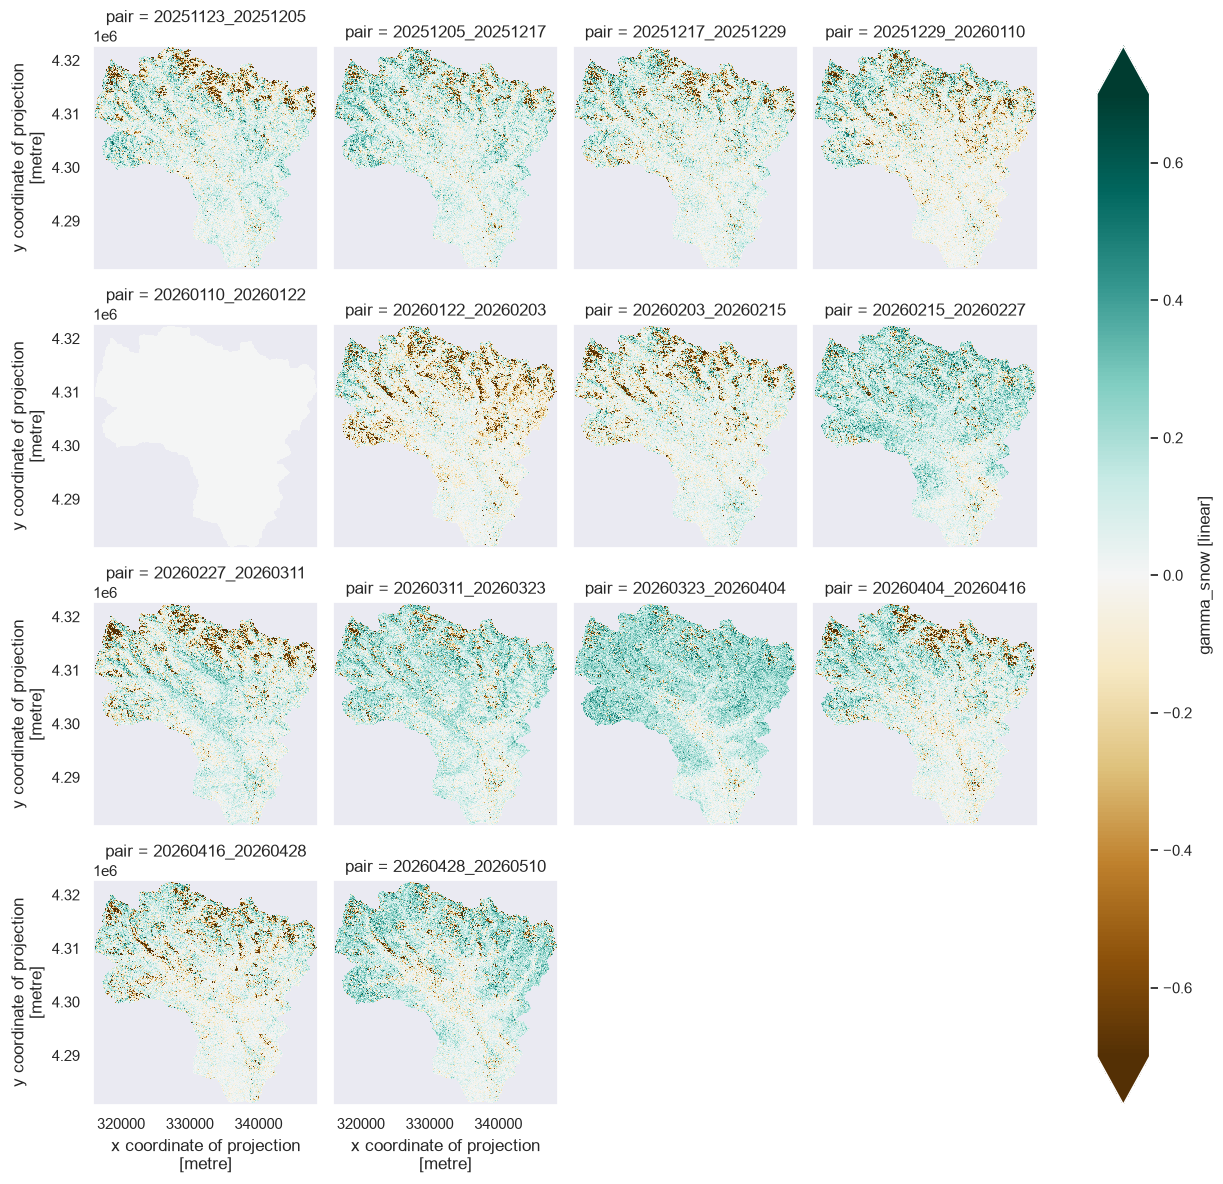

In [87]:
diff = (nisar_20m_reprojected['gamma_snow'].squeeze() - nisar_80m['gamma_snow'].squeeze())
diff.plot(col='pair', col_wrap=4, vmin=-0.7, vmax=0.7, cmap='BrBG')

Plot each step for one pair. 

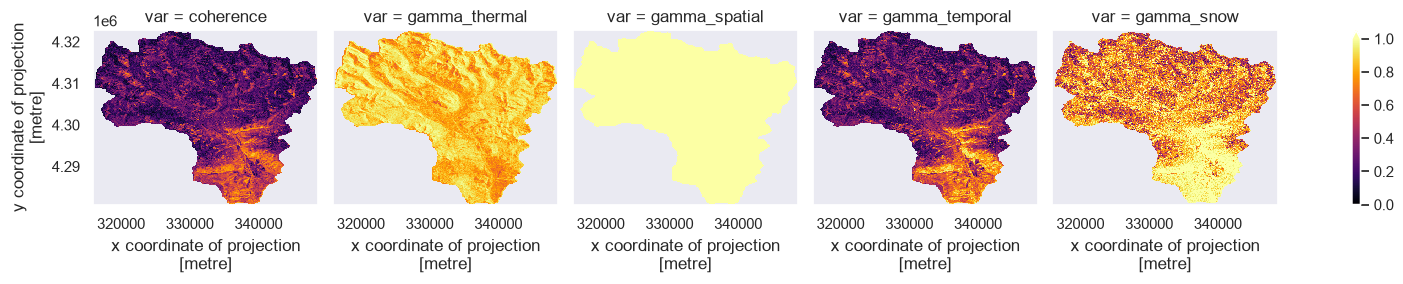

In [39]:
nisar_80m[['coherence', 'gamma_thermal', 'gamma_spatial', 'gamma_temporal', 'gamma_snow']].sel(pair='20260215_20260227').to_array(dim='var').plot(col='var', vmin=0, vmax=1, cmap='inferno')

Save the zarrs. 

In [88]:
nisar_20m.to_zarr(data_dir + 'nisar/zarrs/snow_20m.zarr', mode="w", align_chunks=True)
nisar_80m.to_zarr(data_dir + 'nisar/zarrs/snow_80m.zarr', mode="w", align_chunks=True)

/Users/JULIALOBER/miniforge3/envs/coherence/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=17, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/Users/JULIALOBER/miniforge3/envs/coherence/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/Users/JULIALOBER/miniforge3/envs/coheren